# Day 5: Fine-tuning

On day 4 the transformer stayed frozen and only a logistic regression on top of it learned (test macro F1 0.650). Now all 66M weights of DistilBERT are trained together with a classification head, so the model can reshape its vectors around sentiment.

In [1]:
import copy
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset

from itg_transformers.config import (
    FINE_TUNED_DIR,
    LABELS,
    MAX_LENGTH,
    MODEL_NAME,
    RESULTS_DIR,
)
from itg_transformers.data import load_split
from itg_transformers.embeddings import pick_device
from itg_transformers.finetuning import (
    SentimentDataset,
    evaluate,
    load_classifier,
    predict,
    train_epoch,
)
from itg_transformers.tokenization import load_tokenizer

# The class head is initialized randomly and the batches are shuffled:
# a fixed seed makes every rerun of this notebook give the same model
torch.manual_seed(42)

tokenizer = load_tokenizer()

## 1. Dataset class

A PyTorch `Dataset` answers two questions: how many items there are (`__len__`) and what item number *i* is (`__getitem__`). `SentimentDataset` tokenizes a tweet only when it is requested and returns the tensors the model expects, including `labels`. Every item is padded to the same `max_length`, so a `DataLoader` can stack items into a batch.

In [2]:
train = load_split("train")
dataset = SentimentDataset(
    train["text"].tolist(), train["label"].tolist(), tokenizer
)
print(f"Items: {len(dataset)}, max_length: {MAX_LENGTH}")

item = dataset[0]
for key, value in item.items():
    print(f"{key:15} {tuple(value.shape)} {value.dtype}")

Items: 45615, max_length: 64
input_ids       (64,) torch.int64
attention_mask  (64,) torch.int64
labels          () torch.int64


In [3]:
real = int(item["attention_mask"].sum())
print(train["text"].iloc[0])
label = int(item["labels"])
print(f"Label: {label} ({LABELS[label]})")
print(f"Real tokens: {real}, padding: {MAX_LENGTH - real}")
print(tokenizer.convert_ids_to_tokens(item["input_ids"][: real + 2].tolist()))

QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin
Label: 2 (positive)
Real tokens: 36, padding: 28
['[CLS]', 'q', '##t', '@', 'user', 'in', 'the', 'original', 'draft', 'of', 'the', '7th', 'book', ',', 're', '##mus', 'lu', '##pin', 'survived', 'the', 'battle', 'of', 'hog', '##wart', '##s', '.', '#', 'happy', '##bir', '##th', '##day', '##rem', '##us', '##lu', '##pin', '[SEP]', '[PAD]', '[PAD]']


## 2. Data

The texts and labels come from the official train split (cleaned by `clean_text`). As on day 4, the 80/20 split is made inside it with `stratify` and `random_state=42`, and the official test split stays untouched for day 6.

In [4]:
texts = train["text"].tolist()
labels = train["label"].tolist()

train_texts, val_texts, train_labels, val_labels = train_test_split(
    texts, labels, test_size=0.2, random_state=42, stratify=labels
)

pd.DataFrame(
    {
        "train": pd.Series(train_labels).value_counts(normalize=True),
        "validation": pd.Series(val_labels).value_counts(normalize=True),
    }
).sort_index().rename(index=LABELS).round(3).T.assign(
    size=[len(train_texts), len(val_texts)]
)

,negative,neutral,positive,size
train,0.155,0.453,0.391,36492
validation,0.156,0.453,0.391,9123


`train_test_split` with the same `random_state`, the same labels and the same number of rows picks the same rows, whatever is split alongside the labels. So this validation part is exactly the 20% the day 4 baseline was scored on (macro F1 0.635), and the two can be compared directly:

In [5]:
_, day4_val_rows = train_test_split(
    np.arange(len(labels)), test_size=0.2, random_state=42, stratify=labels
)
same_rows = [texts[row] for row in day4_val_rows] == val_texts
print(f"Same validation tweets as on day 4: {same_rows}")

Same validation tweets as on day 4: True


In [6]:
train_dataset = SentimentDataset(train_texts, train_labels, tokenizer)
val_dataset = SentimentDataset(val_texts, val_labels, tokenizer)
print(f"train_dataset: {len(train_dataset)} items")
print(f"val_dataset: {len(val_dataset)} items")

train_dataset: 36492 items
val_dataset: 9123 items


## 3. Model for classification

`AutoModelForSequenceClassification` loads the same pre-trained DistilBERT as `AutoModel` on days 2-4 and puts a classification head on top. `load_classifier` also stores the label names in the config, so predictions of the saved model read `negative` instead of `LABEL_0`.

In [7]:
num_labels = len(set(labels))
model = load_classifier()

print(f"Model: {MODEL_NAME}, class: {type(model).__name__}")
print(f"num_labels: {num_labels}, id2label: {model.config.id2label}")
print(f"Parameters: {model.num_parameters():,}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: distilbert-base-uncased, class: DistilBertForSequenceClassification
num_labels: 3, id2label: {0: 'negative', 1: 'neutral', 2: 'positive'}
Parameters: 66,955,779


The load report now has two kinds of keys. `UNEXPECTED` is the masked-word head of pre-training, unused as on day 2. `MISSING` is the new classification head: these weights do not exist in the checkpoint and start random. That is the part that must be trained from scratch; the encoder below it only gets adjusted.

In [8]:
for name in ["pre_classifier", "dropout", "classifier"]:
    print(f"{name:15} {model.get_submodule(name)}")

pre_classifier  Linear(in_features=768, out_features=768, bias=True)
dropout         Dropout(p=0.2, inplace=False)
classifier      Linear(in_features=768, out_features=3, bias=True)


The head takes the `[CLS]` vector of the last layer (768 numbers), passes it through `pre_classifier` (768 → 768, ReLU), dropout and `classifier` (768 → 3). The three outputs are *logits*, one score per class; softmax turns them into probabilities. It adds about 0.6M weights to the 66M of the encoder. Unlike day 4, the encoder is not frozen: the gradient of the loss reaches all 67M weights.

### DataLoaders

A `DataLoader` asks the dataset for items and stacks them into batches of 16. `shuffle=True` gives the training batches a new order every epoch; validation keeps a fixed order.

In [9]:
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16)

print(f"Batches per epoch: train {len(train_loader)}")
print(f"Batches per epoch: validation {len(val_loader)}")
batch = next(iter(train_loader))
for key, value in batch.items():
    print(f"{key:15} {tuple(value.shape)}")

Batches per epoch: train 2281
Batches per epoch: validation 571
input_ids       (16, 64)
attention_mask  (16, 64)
labels          (16,)


The untrained head already produces logits, just meaningless ones:

In [10]:
with torch.no_grad():
    untrained = model(
        input_ids=batch["input_ids"][:4],
        attention_mask=batch["attention_mask"][:4],
        labels=batch["labels"][:4],
    )
print(f"Logits:\n{untrained.logits}")
print(f"Probabilities:\n{untrained.logits.softmax(dim=-1)}")
print(f"Loss: {untrained.loss.item():.3f}")
print(f"Loss of a uniform guess, ln 3: {np.log(3):.3f}")

Logits:
tensor([[ 0.0120,  0.0053,  0.0297],
        [-0.0109, -0.0493,  0.0377],
        [ 0.0204, -0.0030,  0.0670],
        [ 0.0346, -0.0797,  0.1037]])
Probabilities:
tensor([[0.3321, 0.3299, 0.3380],
        [0.3320, 0.3195, 0.3485],
        [0.3306, 0.3230, 0.3464],
        [0.3374, 0.3010, 0.3616]])
Loss: 1.066
Loss of a uniform guess, ln 3: 1.099


## 4. Training setup

The task imports `AdamW` from `transformers`. It was deprecated there and removed in transformers 5 (`ImportError` with our version 5.19), in favour of the PyTorch one with the same signature.

In [11]:
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(optimizer)
print(f"Trainable parameters: {trainable:,}")

AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 2e-05
    maximize: False
    weight_decay: 0.01
)
Trainable parameters: 66,955,779


AdamW keeps, for every weight, a running average of its gradients and of their squares, and scales each step by them: weights with noisy gradients move carefully, weights with consistent gradients move faster. *W* stands for decoupled weight decay: every step also shrinks all weights slightly (`weight_decay=0.01` by default in PyTorch), which limits overfitting.

The learning rate 2e-5 is tiny on purpose. The encoder already knows English; large steps would overwrite that knowledge in the first few hundred batches (*catastrophic forgetting*). All 67M weights are trainable, none is frozen.

The task picks CUDA or the CPU. On a Mac that means the CPU, so `pick_device` from day 2 also tries the Apple GPU (MPS):

In [12]:
device = pick_device()
# ty misreads the functools.wraps decorator on PreTrainedModel.to
model.to(device)  # ty: ignore[invalid-argument-type]
print(f"Device: {device}, model on: {model.device}")

Device: mps, model on: mps:0


## 5. Training one epoch

`train_epoch` (in `finetuning.py`) is the training loop of the task. For every batch:

1. `optimizer.zero_grad()` clears the gradients of the previous batch, PyTorch would otherwise add them up;
2. the forward pass with `labels`: the model computes the logits and the cross-entropy loss itself;
3. `loss.backward()` computes the gradient of the loss for all 67M weights (this is why there is no `torch.no_grad()` here);
4. `optimizer.step()` moves every weight a little against its gradient.

`model.train()` at the start switches dropout on (day 2: `eval()` switches it off).

Before training for real, a timing run on 50 batches of a copy of the model, so that the model itself stays untrained:

In [13]:
probe_model = copy.deepcopy(model)
probe_optimizer = torch.optim.AdamW(probe_model.parameters(), lr=2e-5)
probe_loader = DataLoader(
    Subset(train_dataset, range(50 * 16)), batch_size=16, shuffle=True
)

start = time.perf_counter()
probe_loss = train_epoch(probe_model, probe_loader, probe_optimizer, device)
seconds_per_batch = (time.perf_counter() - start) / len(probe_loader)
del probe_model, probe_optimizer

print(f"Mean loss over 50 batches: {probe_loss:.3f}")
print(f"Seconds per batch: {seconds_per_batch:.3f}")
print(f"Estimated epoch: {seconds_per_batch * len(train_loader) / 60:.1f} min")

Mean loss over 50 batches: 1.013
Seconds per batch: 0.141
Estimated epoch: 5.3 min


## 6. Evaluation

`evaluate` returns accuracy and macro F1, as in the task. The loop itself lives in `predict`, which returns the predicted and true labels; `evaluate` scores them, and day 6 will reuse `predict` for the classification report and the confusion matrix.

`model.eval()` switches dropout off and `torch.no_grad()` skips the gradient bookkeeping, as on day 2. No `labels` go into the model: the loss is not needed, only the logits, and the class with the highest logit is the prediction.

The untrained model, as the starting point of training:

In [14]:
start = time.perf_counter()
val_acc, val_f1 = evaluate(model, val_loader, device)
print(f"Val Accuracy: {val_acc:.4f}")
print(f"Val F1: {val_f1:.4f}")
print(f"Evaluation took {time.perf_counter() - start:.0f} s")

untrained_predictions, _ = predict(model, val_loader, device)
print(
    "Predicted classes:",
    pd.Series(untrained_predictions).map(LABELS).value_counts().to_dict(),
)

Val Accuracy: 0.3510
Val F1: 0.2877
Evaluation took 18 s


Predicted classes: {'positive': 5670, 'negative': 3072, 'neutral': 381}


## 7. Training

Three epochs: every epoch is one pass over the 36,492 training tweets, followed by an evaluation on the 9,123 validation tweets.

Training takes about 20 minutes, and a trained model lives only in memory. So the cell saves the model and the tokenizer to `models/fine_tuned_model/` right away (task 8.1), together with the per-epoch metrics. Like `cached_embeddings` on day 4, a rerun of the notebook loads the saved model instead of training again; delete the folder to retrain.

In [15]:
num_epochs = 3
history_path = FINE_TUNED_DIR / "history.json"

if FINE_TUNED_DIR.exists():
    model = load_classifier(str(FINE_TUNED_DIR))
    model.to(device)  # ty: ignore[invalid-argument-type]
    history = json.loads(history_path.read_text())
    print(f"Loaded the trained model from {FINE_TUNED_DIR.name}/")
else:
    history = []
    for epoch in range(num_epochs):
        start = time.perf_counter()
        train_loss = train_epoch(model, train_loader, optimizer, device)
        val_acc, val_f1 = evaluate(model, val_loader, device)
        minutes = (time.perf_counter() - start) / 60

        print(f"Epoch {epoch + 1}/{num_epochs} ({minutes:.1f} min)")
        print(f"Train Loss: {train_loss:.4f}")
        print(f"Val Accuracy: {val_acc:.4f}")
        print(f"Val F1: {val_f1:.4f}")
        print("-" * 50)
        history.append(
            {
                "epoch": epoch + 1,
                "train_loss": train_loss,
                "val_accuracy": val_acc,
                "val_f1": val_f1,
                "minutes": minutes,
            }
        )

    model.save_pretrained(FINE_TUNED_DIR)
    tokenizer.save_pretrained(FINE_TUNED_DIR)
    history_path.write_text(json.dumps(history, indent=2))

history_frame = pd.DataFrame(history).set_index("epoch")
history_frame.round(4)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loaded the trained model from fine_tuned_model/


,train_loss,val_accuracy,val_f1,minutes
epoch,,,,
1,0.6748,0.7070,0.6876,5.4624
2,0.5049,0.7260,0.7004,5.4668
3,0.3413,0.7119,0.6938,5.4831


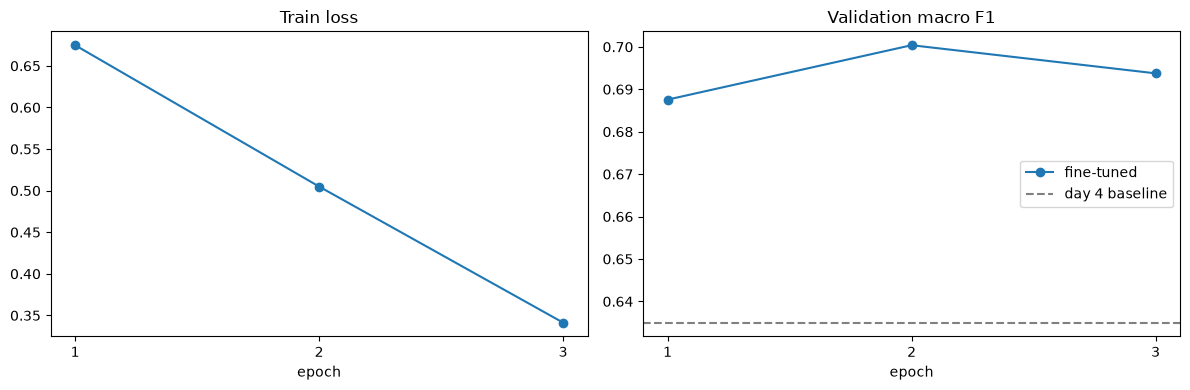

In [16]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
history_frame["train_loss"].plot(ax=left, marker="o", title="Train loss")
history_frame["val_f1"].plot(ax=right, marker="o", label="fine-tuned")
right.axhline(0.635, color="gray", linestyle="--", label="day 4 baseline")
right.set_title("Validation macro F1")
right.legend()
for ax in (left, right):
    ax.set_xticks(history_frame.index)
plt.tight_layout()
plt.show()

Already after one epoch the fine-tuned model beats the day 4 baseline on the very same validation tweets: macro F1 0.688 against 0.635. The best epoch is the second one (0.700).

In epoch 3 the train loss keeps falling fast (0.50 → 0.34), but validation F1 drops slightly (0.700 → 0.694): the model starts to memorise the training tweets instead of learning what generalises. This is the beginning of overfitting; with more epochs the gap would grow. As the task asks, the saved model is the one after the last epoch, so it is slightly worse than the best one.

## 8. Saving the results

The model and the tokenizer were saved right after training (section 7). To make sure the files really hold the trained model, it is loaded back from disk and evaluated again: the numbers must match the last epoch.

In [17]:
saved_model = load_classifier(str(FINE_TUNED_DIR))
saved_model.to(device)  # ty: ignore[invalid-argument-type]
val_acc, val_f1 = evaluate(saved_model, val_loader, device)

last_epoch = history[-1]
print(f"Reloaded model: accuracy {val_acc:.4f}, F1 {val_f1:.4f}")
print(
    f"Last epoch:     accuracy {last_epoch['val_accuracy']:.4f}, "
    f"F1 {last_epoch['val_f1']:.4f}"
)
assert abs(val_f1 - last_epoch["val_f1"]) < 1e-3

print(sorted(path.name for path in FINE_TUNED_DIR.iterdir()))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Reloaded model: accuracy 0.7119, F1 0.6938
Last epoch:     accuracy 0.7119, F1 0.6938
['config.json', 'history.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json']


`fine_tuned_results.txt` gets the two lines from the task plus the training history; `fine_tuned_results.json` keeps the same numbers for day 6. Both go to `results/`, next to the baseline.

In [18]:
best = max(history, key=lambda row: row["val_f1"])
lines = [
    f"Final Validation F1: {val_f1:.4f}",
    f"Final Validation Accuracy: {val_acc:.4f}",
    "",
    f"Model: {MODEL_NAME} fine-tuned for {len(history)} epochs",
    "AdamW lr=2e-5, batch size 16, max_length 64",
    "Validation: 20% stratified split of the train split (random_state=42)",
    f"Best epoch: {best['epoch']} (validation F1 {best['val_f1']:.4f})",
    "",
    history_frame.round(4).to_string(),
]
RESULTS_DIR.mkdir(exist_ok=True)
(RESULTS_DIR / "fine_tuned_results.txt").write_text("\n".join(lines) + "\n")

results = {
    "model": MODEL_NAME,
    "epochs": len(history),
    "split_80_20": {"accuracy": val_acc, "macro_f1": val_f1},
    "history": history,
}
(RESULTS_DIR / "fine_tuned_results.json").write_text(
    json.dumps(results, indent=2)
)
print("\n".join(lines))

Final Validation F1: 0.6938
Final Validation Accuracy: 0.7119

Model: distilbert-base-uncased fine-tuned for 3 epochs
AdamW lr=2e-5, batch size 16, max_length 64
Validation: 20% stratified split of the train split (random_state=42)
Best epoch: 2 (validation F1 0.7004)

       train_loss  val_accuracy  val_f1  minutes
epoch                                           
1          0.6748        0.7070  0.6876   5.4624
2          0.5049        0.7260  0.7004   5.4668
3          0.3413        0.7119  0.6938   5.4831


## 9. The official splits

Day 4 also scored the baseline on the official validation and test splits (test macro F1 0.650). The fine-tuned model on the same tweets, so that day 6 compares like with like. One difference remains: the baseline regression was fitted on the whole train split, the fine-tuned model saw 80% of it.

In [19]:
official_scores = {}
official_predictions = {}
for name in ["validation", "test"]:
    frame = load_split(name)
    loader = DataLoader(
        SentimentDataset(
            frame["text"].tolist(), frame["label"].tolist(), tokenizer
        ),
        batch_size=64,
    )
    predictions, true_labels = predict(saved_model, loader, device)
    official_predictions[name] = (predictions, true_labels)
    official_scores[name] = {
        "accuracy": float((predictions == true_labels).mean()),
        "macro_f1": float(
            classification_report(true_labels, predictions, output_dict=True)[
                "macro avg"
            ]["f1-score"]
        ),
    }

baseline = json.loads((RESULTS_DIR / "baseline_results.json").read_text())
pd.DataFrame(
    {
        "baseline macro F1": {
            name: baseline["official"][name]["macro_f1"]
            for name in official_scores
        },
        "fine-tuned macro F1": {
            name: scores["macro_f1"]
            for name, scores in official_scores.items()
        },
        "fine-tuned accuracy": {
            name: scores["accuracy"]
            for name, scores in official_scores.items()
        },
    }
).round(4)

,baseline macro F1,fine-tuned macro F1,fine-tuned accuracy
validation,0.6319,0.7041,0.7185
test,0.6499,0.6773,0.6796


In [20]:
test_predictions, test_labels = official_predictions["test"]
print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=list(LABELS.values()),
        digits=3,
    )
)

              precision    recall  f1-score   support

    negative      0.678     0.713     0.695      3972
     neutral      0.699     0.656     0.677      5937
    positive      0.639     0.682     0.660      2375

    accuracy                          0.680     12284
   macro avg      0.672     0.684     0.677     12284
weighted avg      0.681     0.680     0.680     12284



The official numbers are added to the results of the day:

In [21]:
results["official"] = official_scores
(RESULTS_DIR / "fine_tuned_results.json").write_text(
    json.dumps(results, indent=2)
)

official_lines = [
    "",
    "Official splits (model trained on 80% of the train split)",
    pd.DataFrame(official_scores).T.round(4).to_string(),
]
with (RESULTS_DIR / "fine_tuned_results.txt").open("a") as file:
    file.write("\n".join(official_lines) + "\n")
print((RESULTS_DIR / "fine_tuned_results.txt").read_text())

Final Validation F1: 0.6938
Final Validation Accuracy: 0.7119

Model: distilbert-base-uncased fine-tuned for 3 epochs
AdamW lr=2e-5, batch size 16, max_length 64
Validation: 20% stratified split of the train split (random_state=42)
Best epoch: 2 (validation F1 0.7004)

       train_loss  val_accuracy  val_f1  minutes
epoch                                           
1          0.6748        0.7070  0.6876   5.4624
2          0.5049        0.7260  0.7004   5.4668
3          0.3413        0.7119  0.6938   5.4831

Official splits (model trained on 80% of the train split)
            accuracy  macro_f1
validation    0.7185    0.7041
test          0.6796    0.6773



Fine-tuning wins on both official splits, but by different margins: +0.07 macro F1 on validation (0.632 → 0.704) and only +0.03 on test (0.650 → 0.677). Validation comes from the same period and topics as train, test does not (US politics of 2016-2017, see `00_eda.ipynb`). The fine-tuned model adapted to the training tweets, which pays off on similar tweets and less on new topics. For the frozen baseline test was not harder than validation (day 4); for the fine-tuned model it is, as the EDA expected.

On test the fine-tuned model is more balanced than the baseline: recall 0.71 / 0.66 / 0.68 for negative / neutral / positive. Day 6 compares the two models in detail.